<a href="https://colab.research.google.com/github/LuxoZppl/herramientasbasicas-zappal-luciano/blob/main/notebooks/An%C3%A1lisis_del_crecimiento_empresarial_%E2%80%94_INC_5000_2019.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introducción

Este proyecto analiza las empresas incluidas en el ranking INC 5000 correspondiente al año 2019.

El objetivo es identificar características y patrones asociados con los niveles de crecimiento de las empresas, considerando variables como industria, ingresos, cantidad de empleados, antigüedad y ubicación geográfica.

El análisis comprende las etapas de carga, limpieza, análisis exploratorio, visualización e interpretación de los datos, y se complementará con un dashboard interactivo desarrollado en Power BI.

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


In [13]:
import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/LuxoZppl/herramientasbasicas-zappal-luciano/main/data/raw/INC5000_limpio%20(1).csv")

print("Dataset cargado correctamente:", df.shape)
display(df.head())

Dataset cargado correctamente: (5012, 17)


,rank,profile,name,url,state,revenue,growth_%,industry,workers,previous_workers,founded,yrs_on_list,metro,city,revenue_millions,company_age_2019,grupo_antiguedad
0,1,https://www.inc.com/profile/freestar,Freestar,http://freestar.com,AZ,36.9 Million,36680.3882,Advertising & Marketing,40.0,5,2015.0,1,Phoenix,Phoenix,36.9,4.0,1–5 años
1,2,https://www.inc.com/profile/freightwise,FreightWise,http://freightwisellc.com,TN,33.6 Million,30547.9317,Logistics & Transportation,39.0,8,2015.0,1,Nashville,Brentwood,33.6,4.0,1–5 años
2,3,https://www.inc.com/profile/ceces-veggie,Cece's Veggie Co.,http://cecesveggieco.com,TX,24.9 Million,23880.4852,Food & Beverage,190.0,10,2015.0,1,Austin,Austin,24.9,4.0,1–5 años
3,4,https://www.inc.com/profile/ladyboss,LadyBoss,http://ladyboss.com,NM,32.4 Million,21849.8925,Consumer Products & Services,57.0,2,2014.0,1,NaN,Albuquerque,32.4,5.0,1–5 años
4,5,https://www.inc.com/profile/perpay,Perpay,http://perpay.com,PA,22.5 Million,18166.4070,Retail,25.0,6,2014.0,1,Philadelphia,Philadelphia,22.5,5.0,1–5 años


In [14]:
import pandas as pd

# Cargar el dataset limpio directamente desde GitHub
url = "https://raw.githubusercontent.com/LuxoZppl/herramientasbasicas-zappal-luciano/main/data/raw/INC5000_limpio%20(1).csv"

df = pd.read_csv(url)

print("Dataset cargado correctamente:", df.shape)
display(df.head())

Dataset cargado correctamente: (5012, 17)


,rank,profile,name,url,state,revenue,growth_%,industry,workers,previous_workers,founded,yrs_on_list,metro,city,revenue_millions,company_age_2019,grupo_antiguedad
0,1,https://www.inc.com/profile/freestar,Freestar,http://freestar.com,AZ,36.9 Million,36680.3882,Advertising & Marketing,40.0,5,2015.0,1,Phoenix,Phoenix,36.9,4.0,1–5 años
1,2,https://www.inc.com/profile/freightwise,FreightWise,http://freightwisellc.com,TN,33.6 Million,30547.9317,Logistics & Transportation,39.0,8,2015.0,1,Nashville,Brentwood,33.6,4.0,1–5 años
2,3,https://www.inc.com/profile/ceces-veggie,Cece's Veggie Co.,http://cecesveggieco.com,TX,24.9 Million,23880.4852,Food & Beverage,190.0,10,2015.0,1,Austin,Austin,24.9,4.0,1–5 años
3,4,https://www.inc.com/profile/ladyboss,LadyBoss,http://ladyboss.com,NM,32.4 Million,21849.8925,Consumer Products & Services,57.0,2,2014.0,1,NaN,Albuquerque,32.4,5.0,1–5 años
4,5,https://www.inc.com/profile/perpay,Perpay,http://perpay.com,PA,22.5 Million,18166.4070,Retail,25.0,6,2014.0,1,Philadelphia,Philadelphia,22.5,5.0,1–5 años


In [15]:
print(df.shape)

(5012, 17)


In [16]:
print(df.columns.tolist())

['rank', 'profile', 'name', 'url', 'state', 'revenue', 'growth_%', 'industry', 'workers', 'previous_workers', 'founded', 'yrs_on_list', 'metro', 'city', 'revenue_millions', 'company_age_2019', 'grupo_antiguedad']


In [17]:
df.head()

,rank,profile,name,url,state,revenue,growth_%,industry,workers,previous_workers,founded,yrs_on_list,metro,city,revenue_millions,company_age_2019,grupo_antiguedad
0,1,https://www.inc.com/profile/freestar,Freestar,http://freestar.com,AZ,36.9 Million,36680.3882,Advertising & Marketing,40.0,5,2015.0,1,Phoenix,Phoenix,36.9,4.0,1–5 años
1,2,https://www.inc.com/profile/freightwise,FreightWise,http://freightwisellc.com,TN,33.6 Million,30547.9317,Logistics & Transportation,39.0,8,2015.0,1,Nashville,Brentwood,33.6,4.0,1–5 años
2,3,https://www.inc.com/profile/ceces-veggie,Cece's Veggie Co.,http://cecesveggieco.com,TX,24.9 Million,23880.4852,Food & Beverage,190.0,10,2015.0,1,Austin,Austin,24.9,4.0,1–5 años
3,4,https://www.inc.com/profile/ladyboss,LadyBoss,http://ladyboss.com,NM,32.4 Million,21849.8925,Consumer Products & Services,57.0,2,2014.0,1,NaN,Albuquerque,32.4,5.0,1–5 años
4,5,https://www.inc.com/profile/perpay,Perpay,http://perpay.com,PA,22.5 Million,18166.4070,Retail,25.0,6,2014.0,1,Philadelphia,Philadelphia,22.5,5.0,1–5 años


In [18]:
df.tail()

,rank,profile,name,url,state,revenue,growth_%,industry,workers,previous_workers,founded,yrs_on_list,metro,city,revenue_millions,company_age_2019,grupo_antiguedad
5007,4996,https://www.inc.com/profile/village-plumbing-air,Village Plumbing & Air,villageplumbing.com,TX,15.8 Million,52.2377,Consumer Products & Services,88.0,62,1946.0,3,Houston,Houston,15.8,73.0,Más de 40 años
5008,4997,https://www.inc.com/profile/real-restoration-g...,Real Restoration Group,realrestoration.com,IL,11.6 Million,52.2127,Construction,380.0,220,2011.0,1,Chicago,Chicago,11.6,8.0,6–10 años
5009,4998,https://www.inc.com/profile/naval-systems,Naval Systems,n-s-i.us,MD,29.7 Million,52.2037,Government Services,187.0,127,2004.0,1,NaN,LEXINGTON PARK,29.7,15.0,11–20 años
5010,4999,https://www.inc.com/profile/hnm-systems,HNM Systems,hnmsystems.com,CA,8.8 Million,52.1919,Telecommunications,132.0,47,2011.0,1,San Diego,Solana Beach,8.8,8.0,6–10 años
5011,5000,https://www.inc.com/profile/vivayic,Vivayic,vivayic.com,NE,4.5 Million,52.1691,Business Products & Services,27.0,22,2006.0,4,NaN,Lincoln,4.5,13.0,11–20 años


In [19]:
df.sample(5, random_state=42)

,rank,profile,name,url,state,revenue,growth_%,industry,workers,previous_workers,founded,yrs_on_list,metro,city,revenue_millions,company_age_2019,grupo_antiguedad
4871,4860,https://www.inc.com/profile/dobi-associates,Dobi & Associates,cedarcraft.com,CA,19.9 Million,56.6566,Business Products & Services,7.0,6,2004.0,4,San Diego,San Diego,19.9,15.0,11–20 años
1025,1023,https://www.inc.com/profile/inseev-interactive,Inseev Interactive,inseev.com,CA,3.8 Million,410.8036,Advertising & Marketing,37.0,4,2013.0,2,San Diego,San Diego,3.8,6.0,6–10 años
3192,3184,https://www.inc.com/profile/emd-strategies,EMD Strategies,emdstrategies.com,VA,3.2 Million,115.1148,Business Products & Services,15.0,7,2009.0,1,"Washington, DC",Arlington,3.2,10.0,6–10 años
2894,2886,https://www.inc.com/profile/birddoghr,BirdDogHR,birddoghr.com,IA,9.7 Million,129.9163,Software,70.0,52,1997.0,5,"Des Moines, IA",Des Moines,9.7,22.0,21–40 años
4392,4381,https://www.inc.com/profile/mortgage-capital-t...,Mortgage Capital Trading,mct-trading.com,CA,19.2 Million,68.5838,Business Products & Services,90.0,71,2001.0,9,NaN,San Diego,19.2,18.0,11–20 años


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5012 entries, 0 to 5011
Data columns (total 17 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   rank              5012 non-null   int64  
 1   profile           5012 non-null   object 
 2   name              5012 non-null   object 
 3   url               5012 non-null   object 
 4   state             5012 non-null   object 
 5   revenue           5012 non-null   object 
 6   growth_%          5012 non-null   float64
 7   industry          5012 non-null   object 
 8   workers           5011 non-null   float64
 9   previous_workers  5012 non-null   int64  
 10  founded           5011 non-null   float64
 11  yrs_on_list       5012 non-null   int64  
 12  metro             4199 non-null   object 
 13  city              5012 non-null   object 
 14  revenue_millions  5012 non-null   float64
 15  company_age_2019  5011 non-null   float64
 16  grupo_antiguedad  5011 non-null   object 


In [21]:
df.describe()

,rank,growth_%,workers,previous_workers,founded,yrs_on_list,revenue_millions,company_age_2019
count,5012.000000,5012.000000,5011.000000,5012.000000,5011.000000,5012.000000,5012.000000,5011.000000
mean,2499.628292,454.680059,242.783077,111.687151,2005.845739,2.813647,47.470830,13.154261
std,1443.232009,1284.288709,2800.165478,1073.878175,10.770364,2.265986,391.334265,10.770364
min,1.000000,52.169100,0.000000,1.000000,1869.000000,1.000000,2.000000,3.000000
25%,1249.750000,90.562500,22.000000,8.000000,2003.000000,1.000000,4.800000,7.000000
50%,2497.500000,157.530650,48.000000,20.000000,2009.000000,2.000000,10.400000,10.000000
75%,3749.250000,330.427250,116.000000,50.000000,2012.000000,4.000000,27.000000,16.000000
max,5000.000000,36680.388200,155000.000000,53000.000000,2016.000000,14.000000,21400.000000,150.000000


In [22]:
df.describe(include="object")

,profile,name,url,state,revenue,industry,metro,city,grupo_antiguedad
count,5012,5012,5012,5012,5012,5012,4199,5012,5011
unique,5012,5012,5012,51,1015,27,70,1558,5
top,https://www.inc.com/profile/vivayic,Vivayic,vivayic.com,CA,2.2 Million,Business Products & Services,New York City,New York,6–10 años
freq,1,1,1,712,64,492,353,165,1971


In [23]:
nulos = df.isna().sum().sort_values(ascending=False)

pct_nulos = (df.isna().mean() * 100).round(2)

tabla_nulos = pd.DataFrame({
    "nulos": nulos,
    "%_nulos": pct_nulos
})

display(tabla_nulos)

,nulos,%_nulos
city,0,0.00
company_age_2019,1,0.02
founded,1,0.02
growth_%,0,0.00
grupo_antiguedad,1,0.02
industry,0,0.00
metro,813,16.22
name,0,0.00
previous_workers,0,0.00
profile,0,0.00


In [24]:
tabla_nulos

,nulos,%_nulos
city,0,0.00
company_age_2019,1,0.02
founded,1,0.02
growth_%,0,0.00
grupo_antiguedad,1,0.02
industry,0,0.00
metro,813,16.22
name,0,0.00
previous_workers,0,0.00
profile,0,0.00


In [25]:
duplicados = df.duplicated().sum()

print(f"Cantidad de filas duplicadas: {duplicados}")

Cantidad de filas duplicadas: 0


In [26]:
df["revenue"].head(10)

,revenue
0,36.9 Million
1,33.6 Million
2,24.9 Million
3,32.4 Million
4,22.5 Million
5,271.8 Million
6,20.5 Million
7,23.3 Million
8,225.9 Million
9,21.4 Million


In [27]:
df["revenue"].value_counts().head(10)

,count
revenue,
2.2 Million,64
2.7 Million,62
2.3 Million,60
2.9 Million,59
2.1 Million,57
3 Million,55
2.5 Million,54
2 Million,53
2.6 Million,51


In [28]:
df["founded"].value_counts().sort_index().head(20)

,count
founded,
1869.0,1
1884.0,1
1895.0,1
1897.0,1
1899.0,1
1902.0,1
1909.0,1
1910.0,1
1914.0,1


In [29]:
df[df["founded"] == 0]

,rank,profile,name,url,state,revenue,growth_%,industry,workers,previous_workers,founded,yrs_on_list,metro,city,revenue_millions,company_age_2019,grupo_antiguedad


In [30]:
df["growth_%"].sort_values(ascending=False).head(10)

,growth_%
0,36680.3882
1,30547.9317
2,23880.4852
3,21849.8925
4,18166.4070
5,14183.4118
6,13480.7310
7,12700.6588
8,12564.5364
9,11996.2964


In [31]:
df.sort_values("growth_%", ascending=False).head(10)[
    ["name", "growth_%", "revenue", "industry", "workers", "founded"]
]

,name,growth_%,revenue,industry,workers,founded
0,Freestar,36680.3882,36.9 Million,Advertising & Marketing,40.0,2015.0
1,FreightWise,30547.9317,33.6 Million,Logistics & Transportation,39.0,2015.0
2,Cece's Veggie Co.,23880.4852,24.9 Million,Food & Beverage,190.0,2015.0
3,LadyBoss,21849.8925,32.4 Million,Consumer Products & Services,57.0,2014.0
4,Perpay,18166.4070,22.5 Million,Retail,25.0,2014.0
5,Cano Health,14183.4118,271.8 Million,Health,742.0,2009.0
6,Bear Mattress,13480.7310,20.5 Million,Consumer Products & Services,12.0,2014.0
7,Connected Solutions Group,12700.6588,23.3 Million,Telecommunications,72.0,2015.0
8,Providence Healthcare Management,12564.5364,225.9 Million,Health,60.0,2008.0
9,NOM,11996.2964,21.4 Million,Advertising & Marketing,37.0,2014.0


In [32]:
df.sort_values("growth_%", ascending=False).head(10)[
    ["name", "growth_%", "revenue", "industry", "workers", "founded"]
]

,name,growth_%,revenue,industry,workers,founded
0,Freestar,36680.3882,36.9 Million,Advertising & Marketing,40.0,2015.0
1,FreightWise,30547.9317,33.6 Million,Logistics & Transportation,39.0,2015.0
2,Cece's Veggie Co.,23880.4852,24.9 Million,Food & Beverage,190.0,2015.0
3,LadyBoss,21849.8925,32.4 Million,Consumer Products & Services,57.0,2014.0
4,Perpay,18166.4070,22.5 Million,Retail,25.0,2014.0
5,Cano Health,14183.4118,271.8 Million,Health,742.0,2009.0
6,Bear Mattress,13480.7310,20.5 Million,Consumer Products & Services,12.0,2014.0
7,Connected Solutions Group,12700.6588,23.3 Million,Telecommunications,72.0,2015.0
8,Providence Healthcare Management,12564.5364,225.9 Million,Health,60.0,2008.0
9,NOM,11996.2964,21.4 Million,Advertising & Marketing,37.0,2014.0


In [33]:
df.sort_values("workers", ascending=False).head(10)[
    ["name", "workers", "previous_workers", "growth_%", "revenue", "industry"]
]

,name,workers,previous_workers,growth_%,revenue,industry
1621,Allied Universal,155000.0,36469,255.1902,5.8 Billion,Security
3752,Alorica,96000.0,53000,90.9001,2.2 Million,Business Products & Services
3403,Infiniti HR,58145.0,21000,104.7641,458 Million,Human Resources
914,Uber Technologies,22263.0,22263,464.9123,11.3 Billion,Consumer Products & Services
3172,ScribeAmerica,20599.0,8958,115.8777,305.1 Million,Health
1336,CircusTrix,14730.0,991,309.4015,194.1 Million,Advertising & Marketing
1118,TaskUs,14098.0,4900,373.5557,254.2 Million,Business Products & Services
4110,Freddy's Frozen Custard,13751.0,7257,77.7525,474.7 Million,Food & Beverage
4010,NFI Industries,10600.0,8100,81.1407,2 Billion,Logistics & Transportation
4985,Pacific Dental Services,10392.0,7036,52.9105,1.4 Billion,Health


In [34]:
df["growth_%"].quantile([0.01, 0.25, 0.50, 0.75, 0.99])

,growth_%
0.01,53.516830
0.25,90.562500
0.50,157.530650
0.75,330.427250
0.99,5446.038642


In [35]:
Q1 = df["growth_%"].quantile(0.25)
Q3 = df["growth_%"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

print(f"Q1: {Q1:.2f}%")
print(f"Q3: {Q3:.2f}%")
print(f"IQR: {IQR:.2f}%")
print(f"Límite inferior: {limite_inferior:.2f}%")
print(f"Límite superior: {limite_superior:.2f}%")

Q1: 90.56%
Q3: 330.43%
IQR: 239.86%
Límite inferior: -269.23%
Límite superior: 690.22%


In [36]:
atipicos_growth = df[df["growth_%"] > limite_superior]

print(f"Cantidad de valores potencialmente atípicos: {len(atipicos_growth)}")
print(f"Porcentaje del dataset: {len(atipicos_growth) / len(df) * 100:.2f}%")

Cantidad de valores potencialmente atípicos: 642
Porcentaje del dataset: 12.81%


In [37]:
atipicos_growth[
    ["name", "growth_%", "revenue", "workers", "previous_workers", "industry"]
].sort_values("growth_%", ascending=False).head(20)

,name,growth_%,revenue,workers,previous_workers,industry
0,Freestar,36680.3882,36.9 Million,40.0,5,Advertising & Marketing
1,FreightWise,30547.9317,33.6 Million,39.0,8,Logistics & Transportation
2,Cece's Veggie Co.,23880.4852,24.9 Million,190.0,10,Food & Beverage
3,LadyBoss,21849.8925,32.4 Million,57.0,2,Consumer Products & Services
4,Perpay,18166.4070,22.5 Million,25.0,6,Retail
5,Cano Health,14183.4118,271.8 Million,742.0,18,Health
6,Bear Mattress,13480.7310,20.5 Million,12.0,1,Consumer Products & Services
7,Connected Solutions Group,12700.6588,23.3 Million,72.0,1,Telecommunications
8,Providence Healthcare Management,12564.5364,225.9 Million,60.0,10,Health
9,NOM,11996.2964,21.4 Million,37.0,5,Advertising & Marketing


In [38]:
df["workers"].quantile([0.01, 0.25, 0.50, 0.75, 0.99])

,workers
0.01,4.0
0.25,22.0
0.50,48.0
0.75,116.0
0.99,2264.6


In [39]:
Q1_workers = df["workers"].quantile(0.25)
Q3_workers = df["workers"].quantile(0.75)

IQR_workers = Q3_workers - Q1_workers

limite_superior_workers = Q3_workers + 1.5 * IQR_workers

print(f"Q1: {Q1_workers:.2f}")
print(f"Q3: {Q3_workers:.2f}")
print(f"IQR: {IQR_workers:.2f}")
print(f"Límite superior: {limite_superior_workers:.2f} empleados")

Q1: 22.00
Q3: 116.00
IQR: 94.00
Límite superior: 257.00 empleados


In [40]:
atipicos_workers = df[df["workers"] > limite_superior_workers]

print(f"Cantidad de empresas: {len(atipicos_workers)}")
print(f"Porcentaje del dataset: {len(atipicos_workers) / len(df) * 100:.2f}%")

Cantidad de empresas: 622
Porcentaje del dataset: 12.41%


In [41]:
df.isna().sum().sort_values(ascending=False)

,0
metro,813
grupo_antiguedad,1
workers,1
founded,1
company_age_2019,1
rank,0
profile,0
url,0
name,0
industry,0


In [42]:
df[df["metro"].isna()][["name", "state", "city", "metro"]].head(20)

,name,state,city,metro
3,LadyBoss,NM,Albuquerque,NaN
20,Tailor Made Compounding,KY,Nicholasville,NaN
21,SD3IT,FL,The Villages,NaN
25,Pegasus Optimization Managers,TX,College Station,NaN
28,LumenAd,MT,Missoula,NaN
32,RDI Technologies,TN,Knoxville,NaN
48,MDstaffers,CA,Rancho Cordova,NaN
61,Chomps,FL,Naples,NaN
63,TradePending,NC,Chapel Hill,NaN
75,Brickell Men's Products,ME,Portland,NaN


In [43]:
df[df["metro"].isna()]["state"].value_counts().head(15)

,count
state,
OR,59
FL,54
CA,50
OH,41
TN,39
NC,37
MI,35
TX,35
CO,31


In [44]:
df[df["workers"].isna()][
    ["name", "workers", "previous_workers", "growth_%", "revenue", "industry"]
]

,name,workers,previous_workers,growth_%,revenue,industry
3755,Mansari,NaN,20,90.7485,2.5 Million,Consumer Products & Services


In [45]:
df[df["founded"] == 0][
    ["name", "founded", "growth_%", "revenue", "industry", "workers"]
]

,name,founded,growth_%,revenue,industry,workers


In [46]:
df["founded"] = df["founded"].replace(0, np.nan)

In [47]:
df.isna().sum().sort_values(ascending=False)

,0
metro,813
grupo_antiguedad,1
workers,1
founded,1
company_age_2019,1
rank,0
profile,0
url,0
name,0
industry,0


In [48]:
df["revenue"].str.extract(r"(Million|Billion)")[0].value_counts()

,count
0,
Million,4989
Billion,23


In [49]:
df["revenue_millions"] = (
    df["revenue"]
    .str.replace(" Million", "", regex=False)
    .str.replace(" Billion", "", regex=False)
    .astype(float)
)

df.loc[df["revenue"].str.contains("Billion"), "revenue_millions"] *= 1000

print(df["revenue_millions"].dtype)

float64


In [50]:
import pandas as pd
import numpy as np

# Cargar el dataset limpio directamente desde GitHub
url = "https://raw.githubusercontent.com/LuxoZppl/herramientasbasicas-zappal-luciano/main/data/raw/INC5000_limpio%20(1).csv"

df = pd.read_csv(url)

print("Dataset cargado correctamente:", df.shape)
display(df.head())

Dataset cargado correctamente: (5012, 17)


,rank,profile,name,url,state,revenue,growth_%,industry,workers,previous_workers,founded,yrs_on_list,metro,city,revenue_millions,company_age_2019,grupo_antiguedad
0,1,https://www.inc.com/profile/freestar,Freestar,http://freestar.com,AZ,36.9 Million,36680.3882,Advertising & Marketing,40.0,5,2015.0,1,Phoenix,Phoenix,36.9,4.0,1–5 años
1,2,https://www.inc.com/profile/freightwise,FreightWise,http://freightwisellc.com,TN,33.6 Million,30547.9317,Logistics & Transportation,39.0,8,2015.0,1,Nashville,Brentwood,33.6,4.0,1–5 años
2,3,https://www.inc.com/profile/ceces-veggie,Cece's Veggie Co.,http://cecesveggieco.com,TX,24.9 Million,23880.4852,Food & Beverage,190.0,10,2015.0,1,Austin,Austin,24.9,4.0,1–5 años
3,4,https://www.inc.com/profile/ladyboss,LadyBoss,http://ladyboss.com,NM,32.4 Million,21849.8925,Consumer Products & Services,57.0,2,2014.0,1,NaN,Albuquerque,32.4,5.0,1–5 años
4,5,https://www.inc.com/profile/perpay,Perpay,http://perpay.com,PA,22.5 Million,18166.4070,Retail,25.0,6,2014.0,1,Philadelphia,Philadelphia,22.5,5.0,1–5 años


In [51]:
df["founded"] = df["founded"].replace(0, np.nan)

print("Años de fundación faltantes:", df["founded"].isna().sum())

Años de fundación faltantes: 1


In [52]:
df["revenue_millions"] = (
    df["revenue"]
    .str.replace(" Million", "", regex=False)
    .str.replace(" Billion", "", regex=False)
    .astype(float)
)

df.loc[
    df["revenue"].str.contains("Billion"),
    "revenue_millions"
] *= 1000

print("Tipo de dato:", df["revenue_millions"].dtype)
print("Empresas con ingresos en millones:",
      df["revenue"].str.contains("Million").sum())
print("Empresas con ingresos en billones:",
      df["revenue"].str.contains("Billion").sum())

Tipo de dato: float64
Empresas con ingresos en millones: 4989
Empresas con ingresos en billones: 23


In [53]:
df[df["revenue"].str.contains("Billion")][
    ["name", "revenue", "revenue_millions"]
].head(10)

,name,revenue,revenue_millions
605,Chewy,3.5 Billion,3500.0
914,Uber Technologies,11.3 Billion,11300.0
1076,Prime Therapeutics,21.4 Billion,21400.0
1621,Allied Universal,5.8 Billion,5800.0
2602,Epiq,1 Billion,1000.0
2664,Fortis Construction,1.2 Billion,1200.0
2730,Kodiak Building Partners,1.1 Billion,1100.0
2793,Strike,1.7 Billion,1700.0
3278,Victra,1.5 Billion,1500.0
3605,Transportation Insight,2.3 Billion,2300.0


In [54]:
print("Ingresos faltantes:", df["revenue_millions"].isna().sum())
print("Ingresos iguales o menores a cero:",
      (df["revenue_millions"] <= 0).sum())

print("\nResumen estadístico:")
display(df["revenue_millions"].describe())

Ingresos faltantes: 0
Ingresos iguales o menores a cero: 0

Resumen estadístico:


,revenue_millions
count,5012.000000
mean,47.470830
std,391.334265
min,2.000000
25%,4.800000
50%,10.400000
75%,27.000000
max,21400.000000


In [55]:
print("Nombres duplicados:", df["name"].duplicated().sum())

Nombres duplicados: 0


In [56]:
print("Cantidad de industrias:", df["industry"].nunique())
print("\nIndustrias disponibles:")
display(df["industry"].value_counts())

Cantidad de industrias: 27

Industrias disponibles:


,count
industry,
Business Products & Services,492
Advertising & Marketing,489
Software,461
Health,356
Construction,350
Consumer Products & Services,315
IT Management,276
Financial Services,239
Government Services,236


In [57]:
df["industry"] = df["industry"].str.strip()

print("Cantidad de industrias:", df["industry"].nunique())

Cantidad de industrias: 27


In [58]:
print("Posiciones faltantes:", df["rank"].isna().sum())
print("Posiciones duplicadas:", df["rank"].duplicated().sum())
print("Posición mínima:", df["rank"].min())
print("Posición máxima:", df["rank"].max())
print("Cantidad de posiciones únicas:", df["rank"].nunique())

Posiciones faltantes: 0
Posiciones duplicadas: 13
Posición mínima: 1
Posición máxima: 5000
Cantidad de posiciones únicas: 4999


In [59]:
df[df["rank"].duplicated(keep=False)][
    ["rank", "name", "industry", "growth_%"]
].sort_values("rank")

,rank,name,industry,growth_%
82,83,Asset Panda,Software,3778.5391
83,83,SeaBay Building Group,Construction,3775.1386
903,903,CentralReach,Software,470.7448
904,903,LMK Clinical Research Consulting,Health,470.2944
1020,1019,Cherry Blow Dry Bar,Consumer Products & Services,413.3721
1021,1019,Applied Development,Government Services,413.3384
1065,1063,Johnson Roofing & Restoration,Construction,393.8611
1066,1063,Street Smart Transmission,Retail,393.7764
1344,1341,Triton Commerce,Advertising & Marketing,308.0838
1345,1341,eAssist Dental Solutions,Health,308.0733


In [60]:
ranks_esperados = set(range(1, 5001))
ranks_existentes = set(df["rank"])

faltantes = sorted(ranks_esperados - ranks_existentes)

print("Cantidad de posiciones faltantes:", len(faltantes))
print("Primeras posiciones faltantes:", faltantes[:20])

Cantidad de posiciones faltantes: 1
Primeras posiciones faltantes: [1892]


In [61]:
print("Empresas con rank 1892:", (df["rank"] == 1892).sum())

print(
    "Cantidad de posiciones repetidas:",
    df["rank"].value_counts().gt(1).sum()
)

Empresas con rank 1892: 0
Cantidad de posiciones repetidas: 13


In [62]:
print("Valores faltantes:", df["yrs_on_list"].isna().sum())
print("Valor mínimo:", df["yrs_on_list"].min())
print("Valor máximo:", df["yrs_on_list"].max())
print("Cantidad de valores distintos:", df["yrs_on_list"].nunique())

display(df["yrs_on_list"].value_counts().sort_index())

Valores faltantes: 0
Valor mínimo: 1
Valor máximo: 14
Cantidad de valores distintos: 14


,count
yrs_on_list,
1,1854
2,1131
3,659
4,479
5,293
6,202
7,132
8,96
9,61


In [63]:
print("Valores faltantes:", df["previous_workers"].isna().sum())
print("Valores iguales o menores a cero:", (df["previous_workers"] <= 0).sum())
print("Valor mínimo:", df["previous_workers"].min())
print("Valor máximo:", df["previous_workers"].max())

Valores faltantes: 0
Valores iguales o menores a cero: 0
Valor mínimo: 1
Valor máximo: 53000


In [64]:
print("Valores faltantes:", df["city"].isna().sum())
print("Ciudades distintas:", df["city"].nunique())

df["city"] = df["city"].str.strip()

print("Ciudades distintas después de quitar espacios:",
      df["city"].nunique())

Valores faltantes: 0
Ciudades distintas: 1558
Ciudades distintas después de quitar espacios: 1558


In [65]:
print("Valores faltantes:", df["state"].isna().sum())
print("Estados distintos:", df["state"].nunique())

df["state"] = df["state"].str.strip()

print("Estados distintos después de quitar espacios:",
      df["state"].nunique())

display(df["state"].value_counts())

Valores faltantes: 0
Estados distintos: 51
Estados distintos después de quitar espacios: 51


,count
state,
CA,712
TX,467
FL,385
NY,300
VA,288
IL,241
GA,219
PA,172
OH,160


In [66]:
print("Valores faltantes:", df["profile"].isna().sum())
print("Categorías distintas:", df["profile"].nunique())

display(df["profile"].value_counts())

Valores faltantes: 0
Categorías distintas: 5012


,count
profile,
https://www.inc.com/profile/vivayic,1
https://www.inc.com/profile/freestar,1
https://www.inc.com/profile/freightwise,1
https://www.inc.com/profile/ceces-veggie,1
https://www.inc.com/profile/dymax,1
...,...
https://www.inc.com/profile/providence-healthcare-management,1
https://www.inc.com/profile/connected-solutions-group,1
https://www.inc.com/profile/bear-mattress,1


In [67]:
print("Valores faltantes:", df["url"].isna().sum())
print("URLs distintas:", df["url"].nunique())

display(df[["name", "url", "profile"]].head(10))

Valores faltantes: 0
URLs distintas: 5012


,name,url,profile
0,Freestar,http://freestar.com,https://www.inc.com/profile/freestar
1,FreightWise,http://freightwisellc.com,https://www.inc.com/profile/freightwise
2,Cece's Veggie Co.,http://cecesveggieco.com,https://www.inc.com/profile/ceces-veggie
3,LadyBoss,http://ladyboss.com,https://www.inc.com/profile/ladyboss
4,Perpay,http://perpay.com,https://www.inc.com/profile/perpay
5,Cano Health,http://canohealth.com,https://www.inc.com/profile/cano-health
6,Bear Mattress,http://bearmattress.com,https://www.inc.com/profile/bear-mattress
7,Connected Solutions Group,http://csgstore.net,https://www.inc.com/profile/connected-solution...
8,Providence Healthcare Management,http://providencehcm.com,https://www.inc.com/profile/providence-healthc...
9,NOM,http://thisisnom.co,https://www.inc.com/profile/nom


In [68]:
df[[
    "name",
    "workers",
    "previous_workers",
    "growth_%"
]].head(10)

,name,workers,previous_workers,growth_%
0,Freestar,40.0,5,36680.3882
1,FreightWise,39.0,8,30547.9317
2,Cece's Veggie Co.,190.0,10,23880.4852
3,LadyBoss,57.0,2,21849.8925
4,Perpay,25.0,6,18166.4070
5,Cano Health,742.0,18,14183.4118
6,Bear Mattress,12.0,1,13480.7310
7,Connected Solutions Group,72.0,1,12700.6588
8,Providence Healthcare Management,60.0,10,12564.5364
9,NOM,37.0,5,11996.2964


In [69]:
df["growth_employees_calc"] = (
    (df["workers"] - df["previous_workers"])
    / df["previous_workers"]
) * 100

display(
    df[[
        "name",
        "workers",
        "previous_workers",
        "growth_%",
        "growth_employees_calc"
    ]].head(10)
)

,name,workers,previous_workers,growth_%,growth_employees_calc
0,Freestar,40.0,5,36680.3882,700.000000
1,FreightWise,39.0,8,30547.9317,387.500000
2,Cece's Veggie Co.,190.0,10,23880.4852,1800.000000
3,LadyBoss,57.0,2,21849.8925,2750.000000
4,Perpay,25.0,6,18166.4070,316.666667
5,Cano Health,742.0,18,14183.4118,4022.222222
6,Bear Mattress,12.0,1,13480.7310,1100.000000
7,Connected Solutions Group,72.0,1,12700.6588,7100.000000
8,Providence Healthcare Management,60.0,10,12564.5364,500.000000
9,NOM,37.0,5,11996.2964,640.000000


In [70]:
comparacion = df[["growth_%", "growth_employees_calc"]].corr()

display(comparacion)

,growth_%,growth_employees_calc
growth_%,1.000000,0.052771
growth_employees_calc,0.052771,1.000000


In [71]:
df["change_employees"] = df["workers"] - df["previous_workers"]

print(
    "Correlación con el cambio absoluto de empleados:",
    df["growth_%"].corr(df["change_employees"])
)

Correlación con el cambio absoluto de empleados: -0.004414257689304612


In [72]:
print("Workers faltantes:", df["workers"].isna().sum())
print("Crecimiento de empleados faltante:",
      df["growth_employees_calc"].isna().sum())
print("Cambio de empleados faltante:",
      df["change_employees"].isna().sum())

Workers faltantes: 1
Crecimiento de empleados faltante: 1
Cambio de empleados faltante: 1


In [73]:
print(df.columns.tolist())

['rank', 'profile', 'name', 'url', 'state', 'revenue', 'growth_%', 'industry', 'workers', 'previous_workers', 'founded', 'yrs_on_list', 'metro', 'city', 'revenue_millions', 'company_age_2019', 'grupo_antiguedad', 'growth_employees_calc', 'change_employees']


In [74]:
df = df.drop(columns=[
    "growth_employees_calc",
    "change_employees"
])

print("Columnas actuales:", df.shape[1])
print(df.columns.tolist())

Columnas actuales: 17
['rank', 'profile', 'name', 'url', 'state', 'revenue', 'growth_%', 'industry', 'workers', 'previous_workers', 'founded', 'yrs_on_list', 'metro', 'city', 'revenue_millions', 'company_age_2019', 'grupo_antiguedad']


In [75]:
print("Tipo de dato:", df["founded"].dtype)
print("Años faltantes:", df["founded"].isna().sum())
print("Año mínimo:", df["founded"].min())
print("Año máximo:", df["founded"].max())

Tipo de dato: float64
Años faltantes: 1
Año mínimo: 1869.0
Año máximo: 2016.0


In [76]:
display(
    df[[
        "growth_%",
        "revenue_millions",
        "workers",
        "previous_workers",
        "founded",
        "yrs_on_list"
    ]].isna().sum()
)

,0
growth_%,0
revenue_millions,0
workers,1
previous_workers,0
founded,1
yrs_on_list,0


In [77]:
resumen_calidad = pd.DataFrame({
    "tipo_dato": df.dtypes.astype(str),
    "valores_faltantes": df.isna().sum(),
    "valores_unicos": df.nunique()
})

display(resumen_calidad)

,tipo_dato,valores_faltantes,valores_unicos
rank,int64,0,4999
profile,object,0,5012
name,object,0,5012
url,object,0,5012
state,object,0,51
revenue,object,0,1015
growth_%,float64,0,5006
industry,object,0,27
workers,float64,1,635
previous_workers,int64,0,443


In [78]:
print("Categorías vacías:", (df["industry"].str.strip() == "").sum())
print("Valores faltantes:", df["industry"].isna().sum())
print("Cantidad de industrias:", df["industry"].nunique())

Categorías vacías: 0
Valores faltantes: 0
Cantidad de industrias: 27


In [79]:
display(
    df["growth_%"].describe(
        percentiles=[0.01, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

,growth_%
count,5012.000000
mean,454.680059
std,1284.288709
min,52.169100
1%,53.516830
25%,90.562500
50%,157.530650
75%,330.427250
90%,868.576490
95%,1701.278630


In [80]:
df.nsmallest(10, "growth_%")[["name", "growth_%", "industry"]]

,name,growth_%,industry
5011,Vivayic,52.1691,Business Products & Services
5010,HNM Systems,52.1919,Telecommunications
5009,Naval Systems,52.2037,Government Services
5008,Real Restoration Group,52.2127,Construction
5007,Village Plumbing & Air,52.2377,Consumer Products & Services
5006,Golden Star Technology,52.3467,IT Services
5005,Gemini Power Systems,52.4300,Telecommunications
5004,Red Six Media,52.4442,Advertising & Marketing
5003,American Thermal Systems,52.4803,Construction
5002,Distillery,52.5232,Software


In [81]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

print("Bibliotecas cargadas correctamente.")

Bibliotecas cargadas correctamente.


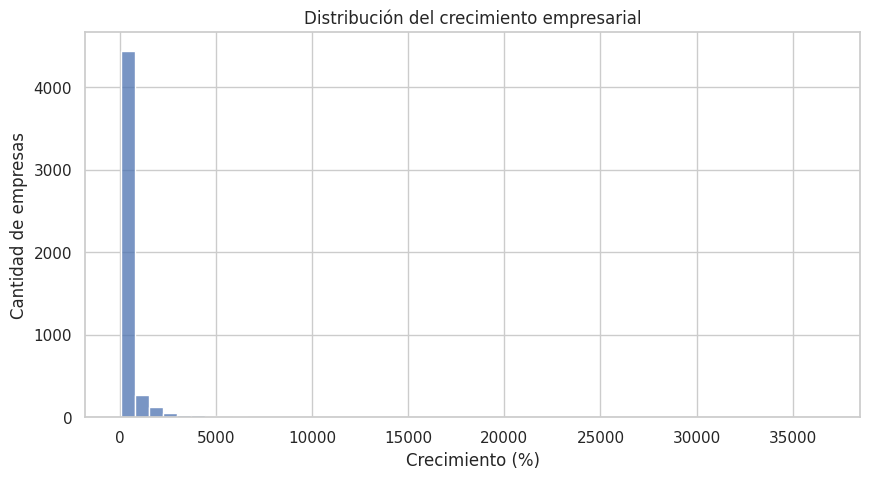

In [82]:
plt.figure(figsize=(10, 5))

sns.histplot(data=df, x="growth_%", bins=50)

plt.title("Distribución del crecimiento empresarial")
plt.xlabel("Crecimiento (%)")
plt.ylabel("Cantidad de empresas")

plt.show()

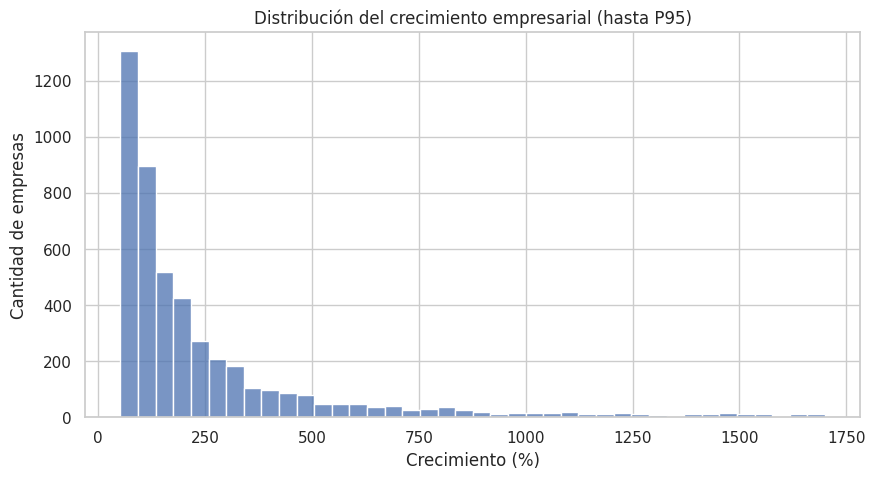

In [83]:
limite_95 = df["growth_%"].quantile(0.95)

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df[df["growth_%"] <= limite_95],
    x="growth_%",
    bins=40
)

plt.title("Distribución del crecimiento empresarial (hasta P95)")
plt.xlabel("Crecimiento (%)")
plt.ylabel("Cantidad de empresas")

plt.show()

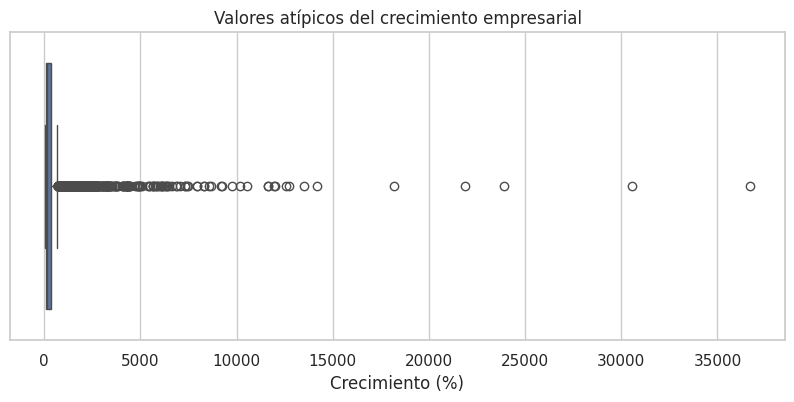

In [84]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=df["growth_%"])

plt.title("Valores atípicos del crecimiento empresarial")
plt.xlabel("Crecimiento (%)")

plt.show()

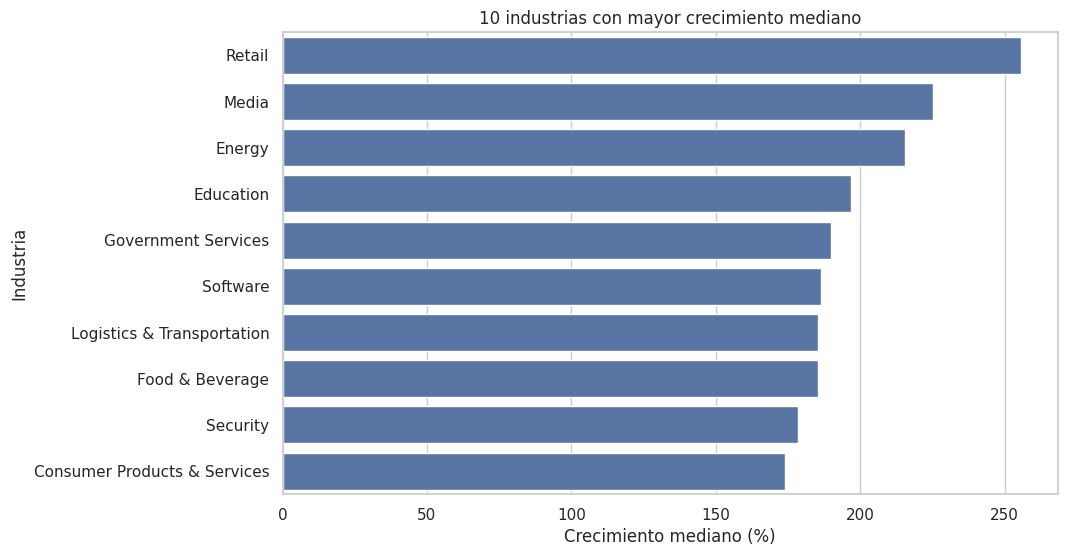

In [85]:
crecimiento_industria = (
    df.groupby("industry")["growth_%"]
    .median()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=crecimiento_industria.values,
    y=crecimiento_industria.index
)

plt.title("10 industrias con mayor crecimiento mediano")
plt.xlabel("Crecimiento mediano (%)")
plt.ylabel("Industria")

plt.show()

In [86]:
cantidad_industria = (
    df.groupby("industry")["growth_%"]
    .agg(["count", "median"])
    .sort_values("median", ascending=False)
    .head(10)
)

display(cantidad_industria)

,count,median
industry,,
Retail,163,255.46290
Media,46,225.06475
Energy,78,215.55615
Education,70,196.62890
Government Services,236,189.67260
Software,461,186.29860
Logistics & Transportation,186,185.25245
Food & Beverage,127,185.16980
Security,67,178.55080


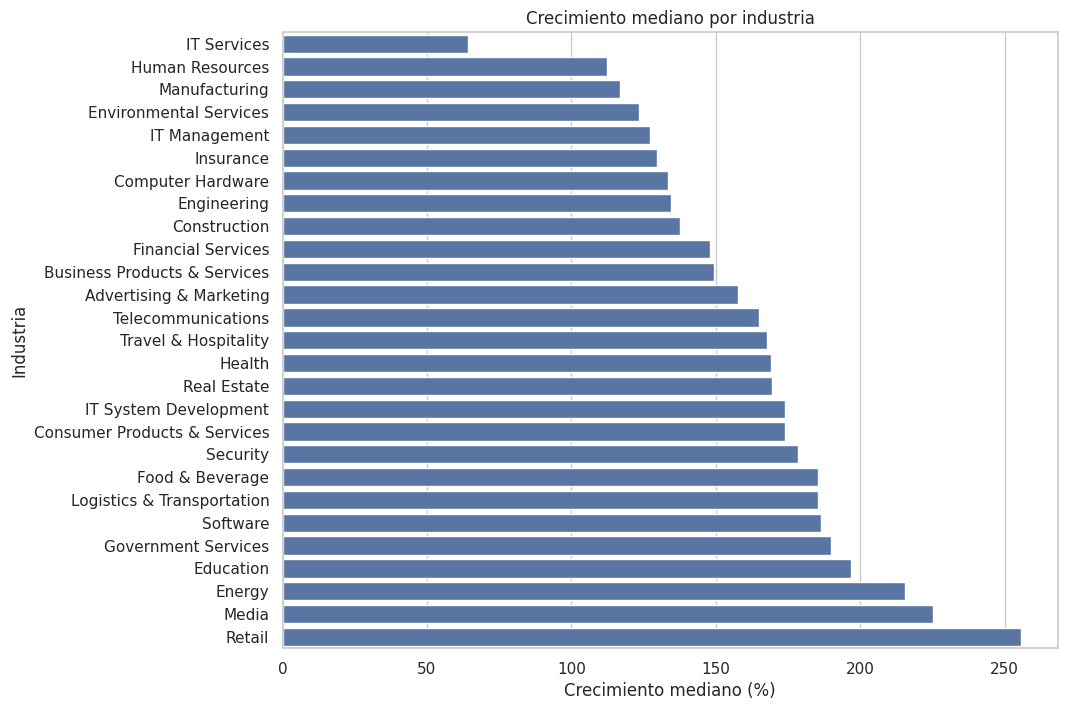

In [87]:
crecimiento_completo = (
    df.groupby("industry")["growth_%"]
    .median()
    .sort_values()
)

plt.figure(figsize=(10, 8))

sns.barplot(
    x=crecimiento_completo.values,
    y=crecimiento_completo.index
)

plt.title("Crecimiento mediano por industria")
plt.xlabel("Crecimiento mediano (%)")
plt.ylabel("Industria")

plt.show()

In [88]:
correlacion_ingresos = df["revenue_millions"].corr(df["growth_%"])

print(
    f"Correlación entre ingresos y crecimiento: "
    f"{correlacion_ingresos:.3f}"
)

Correlación entre ingresos y crecimiento: -0.009


In [89]:
correlacion_empleados = df["workers"].corr(df["growth_%"])

print(
    f"Correlación entre empleados y crecimiento: "
    f"{correlacion_empleados:.3f}"
)

Correlación entre empleados y crecimiento: -0.011


In [90]:
df["company_age_2019"] = 2019 - df["founded"]

print(
    "Correlación entre antigüedad y crecimiento:",
    round(df["company_age_2019"].corr(df["growth_%"]), 3)
)

Correlación entre antigüedad y crecimiento: -0.16


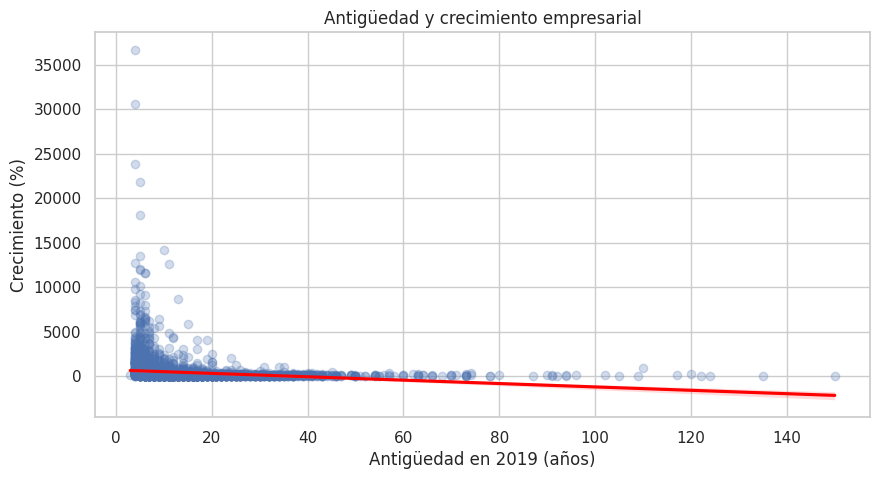

In [91]:
plt.figure(figsize=(10, 5))

sns.regplot(
    data=df,
    x="company_age_2019",
    y="growth_%",
    scatter_kws={"alpha": 0.25},
    line_kws={"color": "red"}
)

plt.title("Antigüedad y crecimiento empresarial")
plt.xlabel("Antigüedad en 2019 (años)")
plt.ylabel("Crecimiento (%)")

plt.show()

In [92]:
df["grupo_antiguedad"] = pd.cut(
    df["company_age_2019"],
    bins=[0, 5, 10, 20, 40, 200],
    labels=[
        "1–5 años",
        "6–10 años",
        "11–20 años",
        "21–40 años",
        "Más de 40 años"
    ]
)

resumen_antiguedad = (
    df.groupby("grupo_antiguedad", observed=False)["growth_%"]
    .agg(["count", "median"])
)

display(resumen_antiguedad)

,count,median
grupo_antiguedad,,
1–5 años,639,591.65330
6–10 años,1971,201.92660
11–20 años,1736,114.72235
21–40 años,546,94.48605
Más de 40 años,119,87.05910


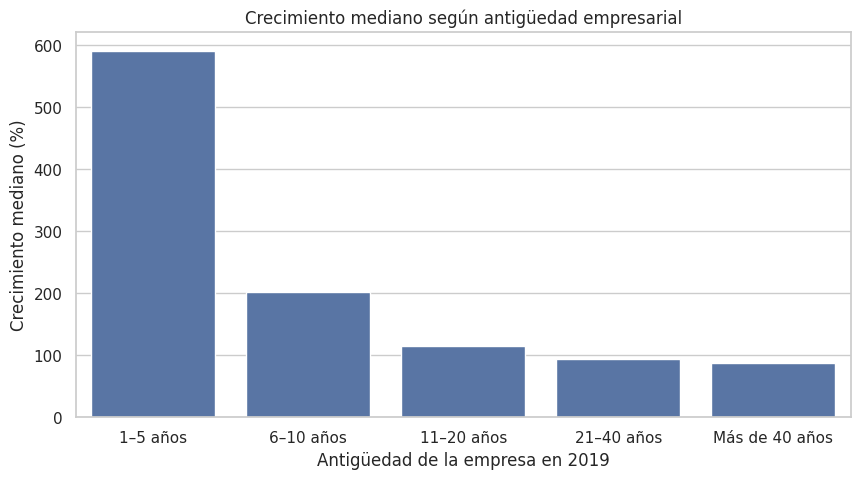

In [93]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=df,
    x="grupo_antiguedad",
    y="growth_%",
    estimator="median",
    errorbar=None
)

plt.title("Crecimiento mediano según antigüedad empresarial")
plt.xlabel("Antigüedad de la empresa en 2019")
plt.ylabel("Crecimiento mediano (%)")

plt.show()

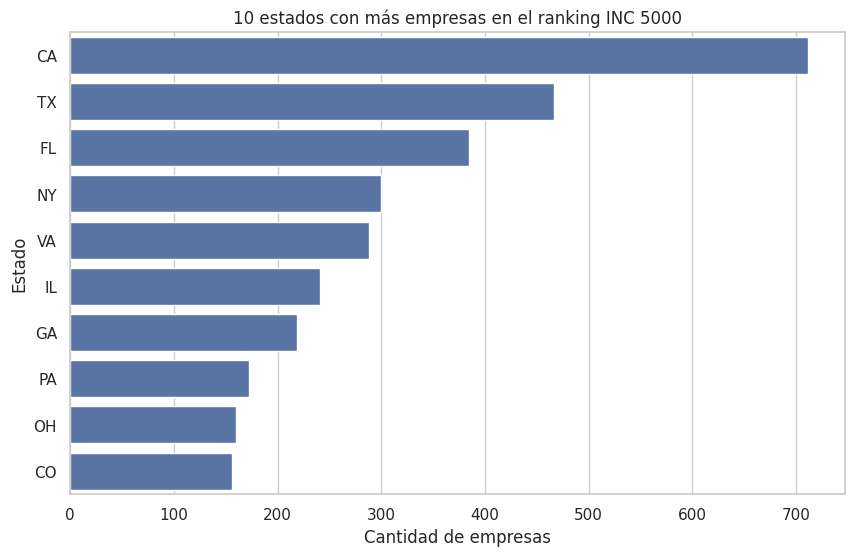

In [94]:
empresas_estado = (
    df["state"]
    .value_counts()
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    x=empresas_estado.values,
    y=empresas_estado.index
)

plt.title("10 estados con más empresas en el ranking INC 5000")
plt.xlabel("Cantidad de empresas")
plt.ylabel("Estado")

plt.show()

In [95]:
top_estados = df["state"].value_counts().head(5).index

crecimiento_estado = (
    df[df["state"].isin(top_estados)]
    .groupby("state")["growth_%"]
    .agg(["count", "median"])
    .sort_values("median", ascending=False)
)

display(crecimiento_estado)

,count,median
state,,
NY,300,181.8659
FL,385,180.1815
CA,712,173.3219
TX,467,161.3777
VA,288,152.5102


In [96]:
correlacion_tamano_ingresos = df[
    ["workers", "revenue_millions"]
].corr()

display(correlacion_tamano_ingresos)

,workers,revenue_millions
workers,1.000000,0.267621
revenue_millions,0.267621,1.000000


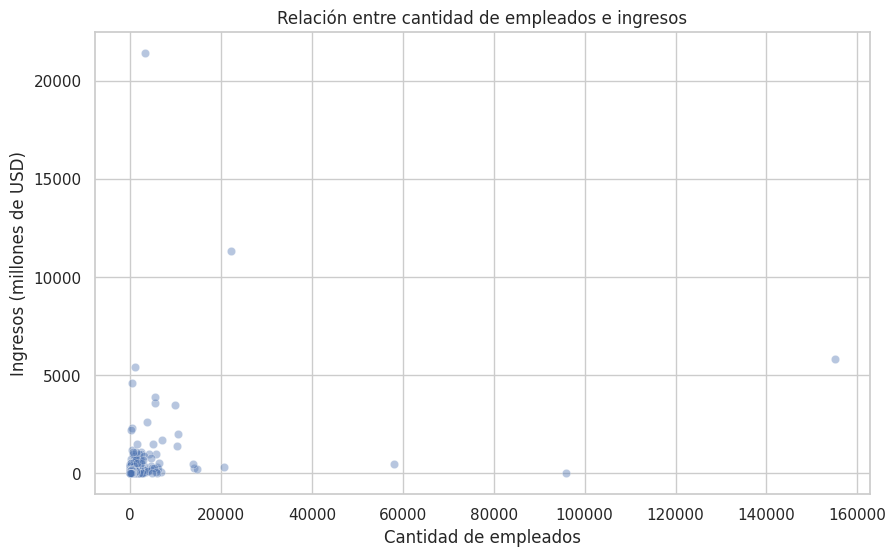

In [97]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="workers",
    y="revenue_millions",
    alpha=0.4
)

plt.title("Relación entre cantidad de empleados e ingresos")
plt.xlabel("Cantidad de empleados")
plt.ylabel("Ingresos (millones de USD)")

plt.show()

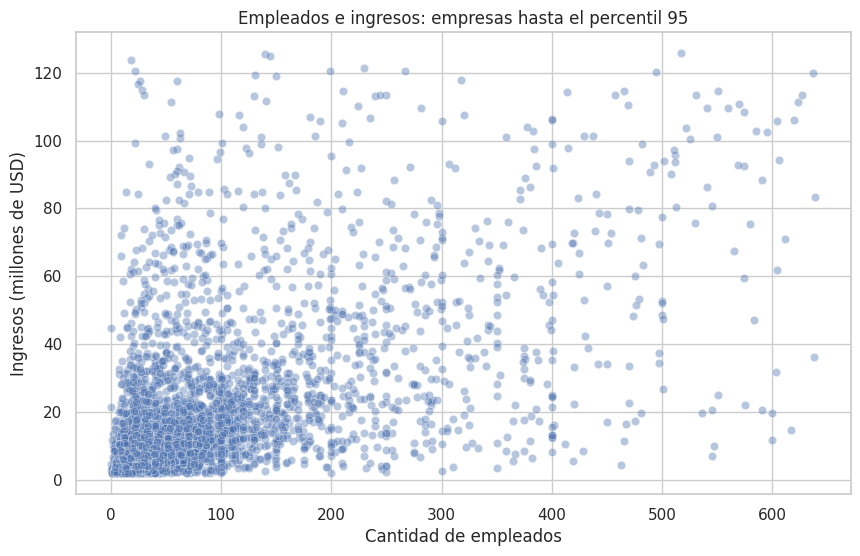

In [98]:
limite_workers = df["workers"].quantile(0.95)
limite_revenue = df["revenue_millions"].quantile(0.95)

df_visual = df[
    (df["workers"] <= limite_workers) &
    (df["revenue_millions"] <= limite_revenue)
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_visual,
    x="workers",
    y="revenue_millions",
    alpha=0.4
)

plt.title("Empleados e ingresos: empresas hasta el percentil 95")
plt.xlabel("Cantidad de empleados")
plt.ylabel("Ingresos (millones de USD)")

plt.show()

In [99]:
print("Empresas en el dataset original:", len(df))
print("Empresas mostradas en el gráfico:", len(df_visual))
print("Empresas fuera del gráfico:", len(df) - len(df_visual))
print(
    "Porcentaje mostrado:",
    round(len(df_visual) / len(df) * 100, 2),
    "%"
)

Empresas en el dataset original: 5012
Empresas mostradas en el gráfico: 4633
Empresas fuera del gráfico: 379
Porcentaje mostrado: 92.44 %


In [100]:
resumen_ranking = (
    df.groupby("yrs_on_list")["growth_%"]
    .agg(["count", "median"])
    .sort_index()
)

display(resumen_ranking)

,count,median
yrs_on_list,,
1,1854,204.13285
2,1131,200.49090
3,659,163.62570
4,479,124.04090
5,293,110.08780
6,202,97.59585
7,132,95.70485
8,96,90.36125
9,61,84.67220


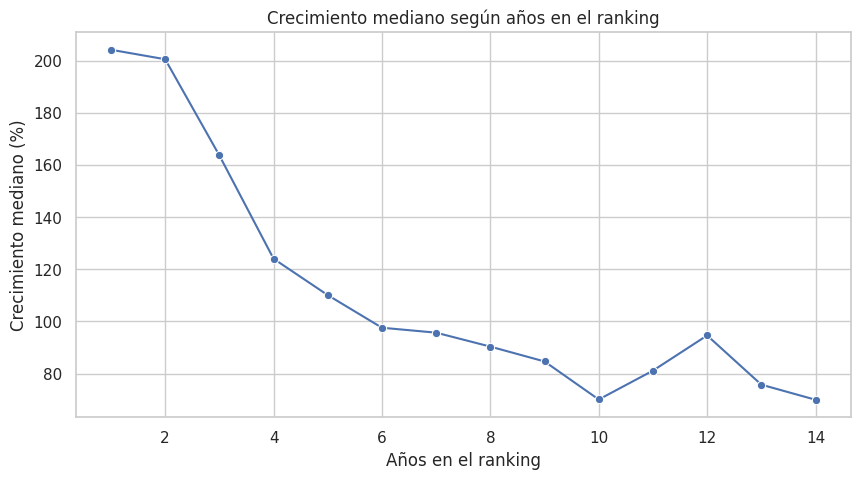

In [101]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=resumen_ranking.reset_index(),
    x="yrs_on_list",
    y="median",
    marker="o"
)

plt.title("Crecimiento mediano según años en el ranking")
plt.xlabel("Años en el ranking")
plt.ylabel("Crecimiento mediano (%)")

plt.show()

In [102]:
print(
    "Correlación entre años en el ranking y crecimiento:",
    round(df["yrs_on_list"].corr(df["growth_%"]), 3)
)

Correlación entre años en el ranking y crecimiento: -0.161


In [103]:
df["change_employees"] = (
    df["workers"] - df["previous_workers"]
)

display(
    df[
        [
            "name",
            "workers",
            "previous_workers",
            "growth_%",
            "change_employees"
        ]
    ].head(10)
)

,name,workers,previous_workers,growth_%,change_employees
0,Freestar,40.0,5,36680.3882,35.0
1,FreightWise,39.0,8,30547.9317,31.0
2,Cece's Veggie Co.,190.0,10,23880.4852,180.0
3,LadyBoss,57.0,2,21849.8925,55.0
4,Perpay,25.0,6,18166.4070,19.0
5,Cano Health,742.0,18,14183.4118,724.0
6,Bear Mattress,12.0,1,13480.7310,11.0
7,Connected Solutions Group,72.0,1,12700.6588,71.0
8,Providence Healthcare Management,60.0,10,12564.5364,50.0
9,NOM,37.0,5,11996.2964,32.0


In [104]:
df["growth_employees_calc"] = (
    (df["workers"] - df["previous_workers"])
    / df["previous_workers"]
) * 100

display(
    df[
        [
            "name",
            "workers",
            "previous_workers",
            "growth_%",
            "growth_employees_calc"
        ]
    ].head(10)
)

,name,workers,previous_workers,growth_%,growth_employees_calc
0,Freestar,40.0,5,36680.3882,700.000000
1,FreightWise,39.0,8,30547.9317,387.500000
2,Cece's Veggie Co.,190.0,10,23880.4852,1800.000000
3,LadyBoss,57.0,2,21849.8925,2750.000000
4,Perpay,25.0,6,18166.4070,316.666667
5,Cano Health,742.0,18,14183.4118,4022.222222
6,Bear Mattress,12.0,1,13480.7310,1100.000000
7,Connected Solutions Group,72.0,1,12700.6588,7100.000000
8,Providence Healthcare Management,60.0,10,12564.5364,500.000000
9,NOM,37.0,5,11996.2964,640.000000


In [105]:
display(
    df.sort_values("growth_%", ascending=False)[
        ["name", "growth_%", "revenue", "workers", "previous_workers"]
    ].head(10)
)

,name,growth_%,revenue,workers,previous_workers
0,Freestar,36680.3882,36.9 Million,40.0,5
1,FreightWise,30547.9317,33.6 Million,39.0,8
2,Cece's Veggie Co.,23880.4852,24.9 Million,190.0,10
3,LadyBoss,21849.8925,32.4 Million,57.0,2
4,Perpay,18166.4070,22.5 Million,25.0,6
5,Cano Health,14183.4118,271.8 Million,742.0,18
6,Bear Mattress,13480.7310,20.5 Million,12.0,1
7,Connected Solutions Group,12700.6588,23.3 Million,72.0,1
8,Providence Healthcare Management,12564.5364,225.9 Million,60.0,10
9,NOM,11996.2964,21.4 Million,37.0,5


### Validación de la variable growth_%

Según la metodología del ranking INC 5000 de 2019, la variable growth_% representa el crecimiento porcentual de los ingresos entre 2015 y 2018.

Por lo tanto, no debe interpretarse como el crecimiento de la cantidad de empleados. La variable workers y previous_workers describen la evolución del personal, mientras que growth_% mide el crecimiento de los ingresos.

Esta distinción es importante para evitar interpretaciones incorrectas y para definir adecuadamente las comparaciones del análisis.

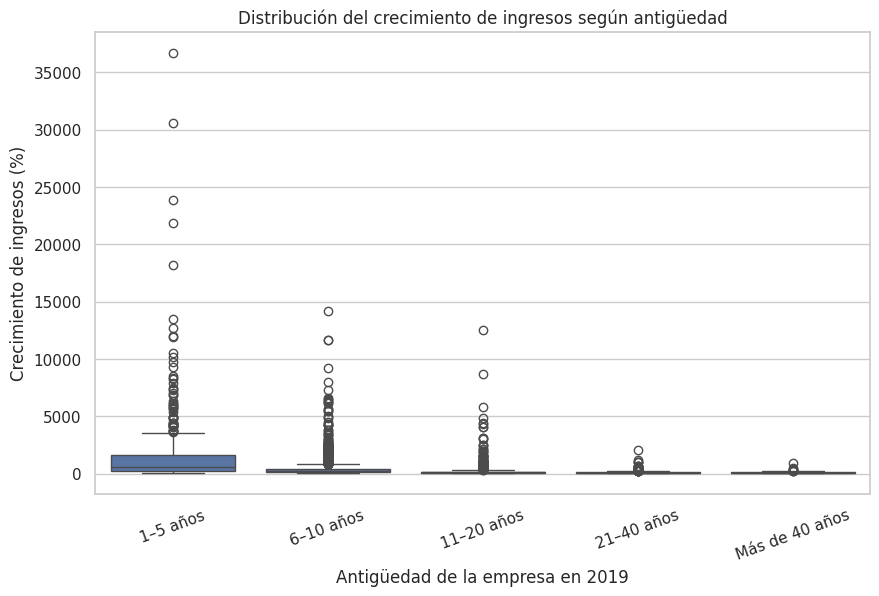

In [106]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="grupo_antiguedad",
    y="growth_%"
)

plt.title("Distribución del crecimiento de ingresos según antigüedad")
plt.xlabel("Antigüedad de la empresa en 2019")
plt.ylabel("Crecimiento de ingresos (%)")
plt.xticks(rotation=20)

plt.show()

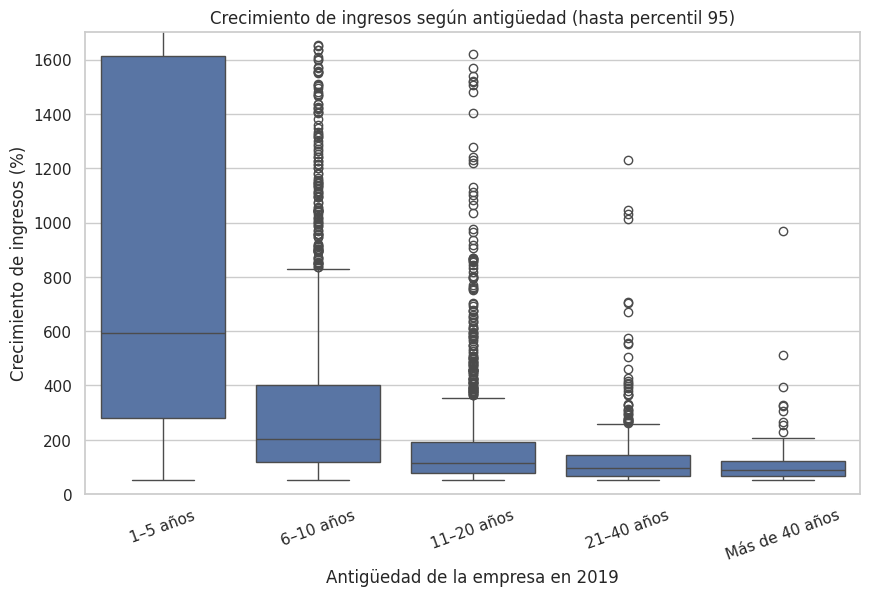

In [107]:
limite_95 = df["growth_%"].quantile(0.95)

plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="grupo_antiguedad",
    y="growth_%"
)

plt.ylim(0, limite_95)

plt.title("Crecimiento de ingresos según antigüedad (hasta percentil 95)")
plt.xlabel("Antigüedad de la empresa en 2019")
plt.ylabel("Crecimiento de ingresos (%)")
plt.xticks(rotation=20)

plt.show()

In [108]:
resumen_industria = (
    df.groupby("industry", observed=True)
    .agg(
        cantidad_empresas=("name", "count"),
        crecimiento_mediano=("growth_%", "median"),
        crecimiento_promedio=("growth_%", "mean")
    )
    .sort_values("crecimiento_mediano", ascending=False)
)

display(resumen_industria.head(10).round(2))

,cantidad_empresas,crecimiento_mediano,crecimiento_promedio
industry,,,
Retail,163,255.46,584.82
Media,46,225.06,413.73
Energy,78,215.56,592.08
Education,70,196.63,384.56
Government Services,236,189.67,485.31
Software,461,186.30,524.67
Logistics & Transportation,186,185.25,717.56
Food & Beverage,127,185.17,668.23
Security,67,178.55,490.19


### Interpretación del crecimiento según industria

Retail presenta el mayor crecimiento mediano de ingresos, con un 255,46%, seguido por Media (225,06%) y Energy (215,56%). Software, aunque ocupa el sexto lugar por crecimiento mediano (186,30%), es la industria con mayor cantidad de empresas entre las diez primeras, con 461 registros.

Se observan diferencias importantes entre el crecimiento mediano y el promedio. Por ejemplo, Logistics & Transportation presenta una mediana del 185,25% y un promedio del 717,56%. Esta diferencia sugiere la influencia de valores extremos en el promedio.

Por lo tanto, la mediana resulta una medida útil para comparar industrias sin que unas pocas empresas con crecimientos excepcionalmente altos distorsionen tanto los resultados. Estas diferencias describen asociaciones dentro del ranking analizado y no implican causalidad.

In [109]:
correlacion = df["workers"].corr(df["revenue_millions"])

print(f"Correlación entre empleados e ingresos: {correlacion:.3f}")

Correlación entre empleados e ingresos: 0.268


### Interpretación de la relación entre empleados e ingresos

La correlación de Pearson entre la cantidad de empleados y los ingresos es de 0,268, lo que indica una asociación lineal positiva débil. Esto sugiere que las empresas con más empleados tienden a registrar mayores ingresos, aunque la relación presenta una intensidad limitada.

Este resultado no implica que una mayor cantidad de empleados cause mayores ingresos. Además, pueden existir otras características empresariales que ayuden a explicar las diferencias observadas.

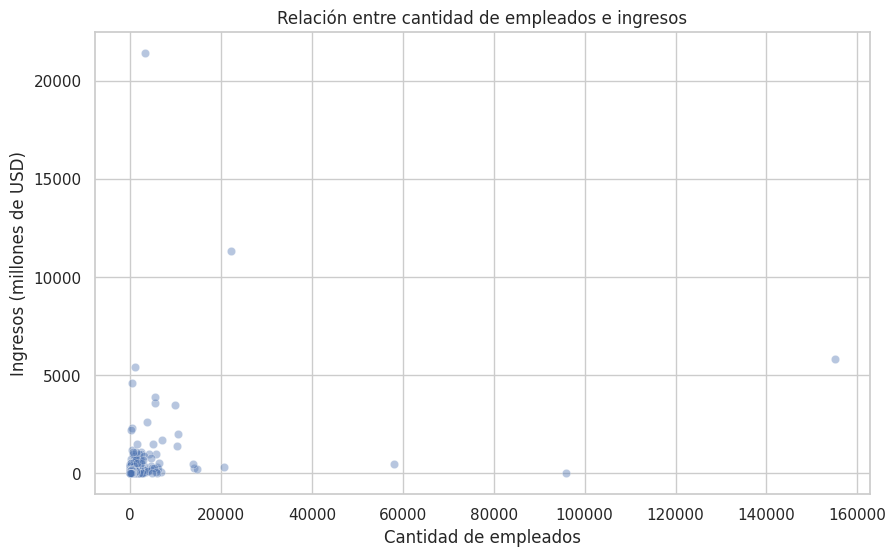

In [110]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="workers",
    y="revenue_millions",
    alpha=0.4
)

plt.title("Relación entre cantidad de empleados e ingresos")
plt.xlabel("Cantidad de empleados")
plt.ylabel("Ingresos (millones de USD)")

plt.show()

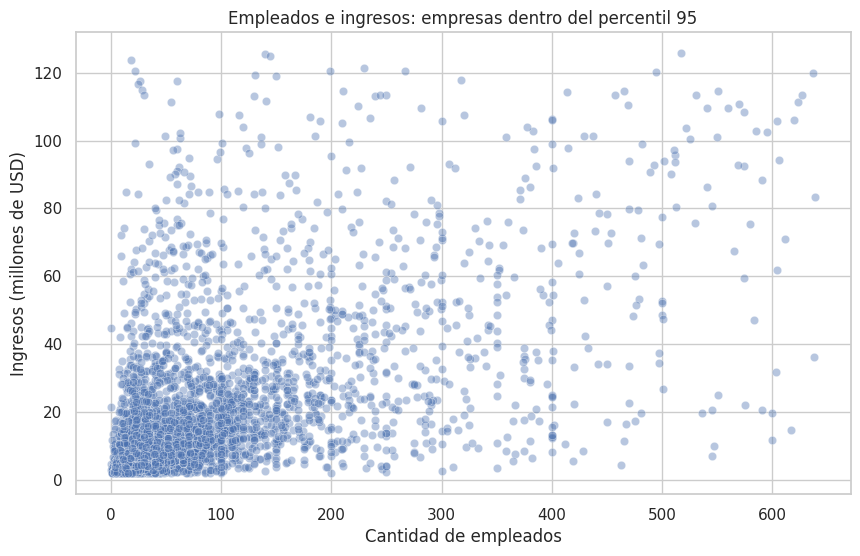

Empresas representadas: 4633 de 5012


In [111]:
limite_empleados = df["workers"].quantile(0.95)
limite_ingresos = df["revenue_millions"].quantile(0.95)

df_zoom = df[
    (df["workers"] <= limite_empleados) &
    (df["revenue_millions"] <= limite_ingresos)
]

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_zoom,
    x="workers",
    y="revenue_millions",
    alpha=0.4
)

plt.title("Empleados e ingresos: empresas dentro del percentil 95")
plt.xlabel("Cantidad de empleados")
plt.ylabel("Ingresos (millones de USD)")

plt.show()

print(f"Empresas representadas: {len(df_zoom)} de {len(df)}")

### Interpretación de la relación entre empleados e ingresos

El gráfico de dispersión muestra una concentración de empresas con menos de 200 empleados y con ingresos inferiores a 40 millones de USD. Sin embargo, también se observan empresas con ingresos considerablemente mayores dentro de rangos similares de personal.

La correlación de Pearson de 0,268 indica una asociación lineal positiva débil entre ambas variables. Por lo tanto, la cantidad de empleados, por sí sola, no permite explicar completamente las diferencias de ingresos entre las empresas.

Para mejorar la visualización, se representó el 92,44% de las empresas, limitando los valores de ambas variables al percentil 95. Esta decisión afecta únicamente al gráfico y no elimina registros del conjunto de datos original.

In [112]:
resumen_general = pd.DataFrame({
    "Indicador": [
        "Cantidad de empresas",
        "Cantidad de industrias",
        "Crecimiento mediano de ingresos (%)",
        "Crecimiento promedio de ingresos (%)",
        "Mediana de empleados",
        "Mediana de ingresos (millones USD)",
        "Antigüedad mediana en el ranking (años)"
    ],
    "Valor": [
        df["name"].nunique(),
        df["industry"].nunique(),
        df["growth_%"].median(),
        df["growth_%"].mean(),
        df["workers"].median(),
        df["revenue_millions"].median(),
        df["yrs_on_list"].median()
    ]
})

display(resumen_general.round(2))

,Indicador,Valor
0,Cantidad de empresas,5012.00
1,Cantidad de industrias,27.00
2,Crecimiento mediano de ingresos (%),157.53
3,Crecimiento promedio de ingresos (%),454.68
4,Mediana de empleados,48.00
5,Mediana de ingresos (millones USD),10.40
6,Antigüedad mediana en el ranking (años),2.00


### Resumen general de los resultados

El conjunto de datos contiene 5.012 empresas distribuidas en 27 industrias. La empresa representativa según la mediana presenta un crecimiento de ingresos del 157,53%, ingresos por 10,4 millones de USD y 48 empleados. La antigüedad mediana en el ranking es de dos años.

El crecimiento promedio de ingresos alcanza el 454,68%, un valor considerablemente superior a la mediana. Esta diferencia evidencia una distribución asimétrica, influida por empresas con tasas de crecimiento excepcionalmente altas. Por este motivo, la mediana resulta especialmente útil para describir el comportamiento central de las empresas analizadas.

Estos resultados describen las empresas incluidas en el ranking INC 5000 de 2019 y no deben generalizarse automáticamente a todas las empresas.

In [113]:
import pandas as pd

df = pd.read_csv("https://raw.githubusercontent.com/LuxoZppl/herramientasbasicas-zappal-luciano/main/data/raw/INC5000_limpio%20(1).csv")

print("Dataset cargado:", df.shape)

Dataset cargado: (5012, 17)


In [114]:
print("Filas:", len(df))
print("Columnas:", len(df.columns))
print("Duplicados:", df.duplicated().sum())
print("Valores faltantes:", df.isna().sum().sum())

Filas: 5012
Columnas: 17
Duplicados: 0
Valores faltantes: 817


In [115]:
print("Filas:", len(df))
print("Columnas:", len(df.columns))
print("Duplicados:", df.duplicated().sum())
print("Valores faltantes:", df.isna().sum().sum())

Filas: 5012
Columnas: 17
Duplicados: 0
Valores faltantes: 817


In [116]:
faltantes = df.isna().sum()

resumen_faltantes = (
    faltantes[faltantes > 0]
    .sort_values(ascending=False)
    .to_frame(name="Valores faltantes")
)

resumen_faltantes["Porcentaje (%)"] = (
    resumen_faltantes["Valores faltantes"] / len(df) * 100
).round(2)

display(resumen_faltantes)

,Valores faltantes,Porcentaje (%)
metro,813,16.22
workers,1,0.02
founded,1,0.02
company_age_2019,1,0.02
grupo_antiguedad,1,0.02


In [117]:
import pandas as pd

# Cargar el dataset limpio directamente desde GitHub
url = "https://raw.githubusercontent.com/LuxoZppl/herramientasbasicas-zappal-luciano/main/data/raw/INC5000_limpio%20(1).csv"

df = pd.read_csv(url)

print("Dataset cargado:", df.shape)

Dataset cargado: (5012, 17)


In [118]:

# Eliminar columnas auxiliares de la exploración
df = df.drop(
    columns=["change_employees", "growth_employees_calc"],
    errors="ignore"
)

# Control de calidad final
control_final = pd.DataFrame({
    "Tipo de dato": df.dtypes.astype(str),
    "Valores faltantes": df.isna().sum(),
    "Valores únicos": df.nunique()
})

print("CONTROL DE CALIDAD FINAL")
display(control_final)

print("\nFilas duplicadas:", df.duplicated().sum())
print("Cantidad de filas:", df.shape[0])
print("Cantidad de columnas:", df.shape[1])


CONTROL DE CALIDAD FINAL


,Tipo de dato,Valores faltantes,Valores únicos
rank,int64,0,4999
profile,object,0,5012
name,object,0,5012
url,object,0,5012
state,object,0,51
revenue,object,0,1015
growth_%,float64,0,5006
industry,object,0,27
workers,float64,1,635
previous_workers,int64,0,443



Filas duplicadas: 0
Cantidad de filas: 5012
Cantidad de columnas: 17


In [119]:
df = df.drop(
    columns=["change_employees", "growth_employees_calc"],
    errors="ignore"
)

print("Columnas después de la limpieza:", df.shape[1])

Columnas después de la limpieza: 17


In [120]:
print(df.columns.tolist())

['rank', 'profile', 'name', 'url', 'state', 'revenue', 'growth_%', 'industry', 'workers', 'previous_workers', 'founded', 'yrs_on_list', 'metro', 'city', 'revenue_millions', 'company_age_2019', 'grupo_antiguedad']


### Limpieza y preparación de los datos

El conjunto de datos original contiene 5.012 registros y 14 columnas. Durante la preparación se revisaron los valores faltantes, los registros duplicados, los tipos de datos y los posibles valores extremos.

Se detectaron 813 valores faltantes en la variable `metro`, un valor faltante en `workers` y un valor de `founded` igual a cero, que se consideró inválido y se reemplazó por un valor faltante. No se eliminaron empresas por presentar valores extremos de crecimiento, ya que no se encontró evidencia suficiente para considerarlos errores.

La variable `revenue` se convirtió a un formato numérico expresado en millones de USD para facilitar los cálculos. También se crearon variables derivadas para analizar la antigüedad de las empresas en 2019.

Finalmente, se eliminaron dos columnas auxiliares utilizadas durante la exploración. El conjunto de datos conserva las 5.012 filas originales y no presenta filas completamente duplicadas.

## Conclusiones preliminares

El análisis exploratorio del ranking INC 5000 de 2019 permitió identificar patrones asociados con el crecimiento de los ingresos de las empresas.

En primer lugar, el crecimiento presenta una distribución muy asimétrica: la mediana fue del 157,53%, mientras que el promedio alcanzó el 454,68%. Esto indica que algunas empresas con crecimientos excepcionalmente altos elevan considerablemente el promedio.

En segundo lugar, se observaron diferencias entre industrias. Retail presentó el mayor crecimiento mediano entre las diez industrias analizadas en la tabla comparativa, con un 255,46%, seguida por Media y Energy.

También se encontró una asociación negativa débil entre la antigüedad de las empresas y el crecimiento de sus ingresos. Las empresas de menor antigüedad mostraron medianas de crecimiento más altas dentro de la muestra.

Por último, la cantidad de empleados presentó una asociación lineal positiva débil con los ingresos (correlación de Pearson de 0,268). Esto sugiere que el tamaño de la plantilla, por sí solo, no explica completamente las diferencias de ingresos entre las empresas.

Estos resultados describen asociaciones y patrones observados en el ranking analizado; no permiten establecer relaciones causales ni generalizar automáticamente los resultados a todas las empresas.

In [121]:
df.to_csv("INC5000_limpio.csv", index=False)

print("Archivo exportado correctamente")

Archivo exportado correctamente


In [122]:
from google.colab import files
files.download("INC5000_limpio.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>